# 04 — Trading Simulation
Four backtests:
1. `sim_vectorized` — vectorized long-only (sim1/sim2 style)
2. `sim_exact` — row-iter with reinvestment & fees
3. `sim_risk_managed` — stop-loss + Kelly sizing + macro regime filter, benchmarked vs equal-weight universe (DAX proxy)

Outputs: `reports/sim_summary.csv`, `reports/equity_curve.csv`, `reports/benchmark_curve.csv`.

In [1]:
# Kernel bootstrap — run first
import sys, os
def _find_root():
    for base in [os.getcwd(), os.path.abspath(".."), os.path.abspath(".")]:
        for cand in [base, os.path.dirname(base)]:
            if os.path.isfile(os.path.join(cand, "requirements.txt")) and os.path.isdir(os.path.join(cand, "src")):
                return cand
    return os.path.abspath("..")
_project_root = _find_root()
if _project_root not in sys.path: sys.path.insert(0, _project_root)
os.chdir(_project_root)
from src.bootstrap import ensure
ensure({'pandas_datareader':'pandas-datareader','ta':'ta','yaml':'pyyaml',
        'yfinance':'yfinance','xgboost':'xgboost','optuna':'optuna',
        'matplotlib':'matplotlib'})
print("bootstrap OK  project_root =", _project_root)


bootstrap OK  project_root = /home/yazadanparast/Downloads/eu-midcap-echo


In [2]:
%load_ext autoreload
%autoreload 2
import subprocess, sys
# Make sure features exist before simulating
from pathlib import Path
if not Path('data/processed/df_combined.parquet').exists():
    print('building features first...')
    from src.features.build_features import build_dataset
    build_dataset()
print('running simulate stage (auto-retrains model if stale)...')
r = subprocess.run([sys.executable, 'scripts/run_pipeline.py', '--simulate-only'],
                   capture_output=True, text=True, cwd=_project_root)
print('STDOUT (tail):'); print(r.stdout[-3000:])
if r.returncode != 0:
    print('STDERR (tail):'); print(r.stderr[-2000:])


running simulate stage (auto-retrains model if stale)...
STDOUT (tail):



In [3]:
%load_ext autoreload
%autoreload 2
import pandas as pd, os
sum_path = os.path.join(_project_root, 'reports/sim_summary.csv')
if os.path.exists(sum_path):
    summary = pd.read_csv(sum_path)
    print('sim summary:'); print(summary.to_string(index=False))
else:
    print('sim_summary.csv not found — simulation may have failed; see stderr above.')


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
sim summary:
                          strategy     n          net  mean_per_day  q75_per_day  capital     CAGR   Sharpe  Sortino     MaxDD         Final  n_trades  win_rate  benchmark_CAGR  benchmark_Sharpe  benchmark_Final  alpha_vs_bench
                 pred_xgb_best_0.5 21398 25507.921875     29.514483         45.0 100000.0 0.069955      NaN      NaN -0.051332 125381.976562     21398  0.542247             NaN               NaN              NaN             NaN
                pred_xgb_best_0.55 16915 21203.683594     24.838473         36.0 100000.0 0.058908      NaN      NaN -0.038283 121103.429688     16915  0.545610             NaN               NaN              NaN             NaN
                 pred_xgb_best_0.6 12939 18346.207031     20.029412         28.0 100000.0 0.051515      NaN      NaN -0.027630 118298.320312     12939  0.549579             NaN               NaN              NaN    

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


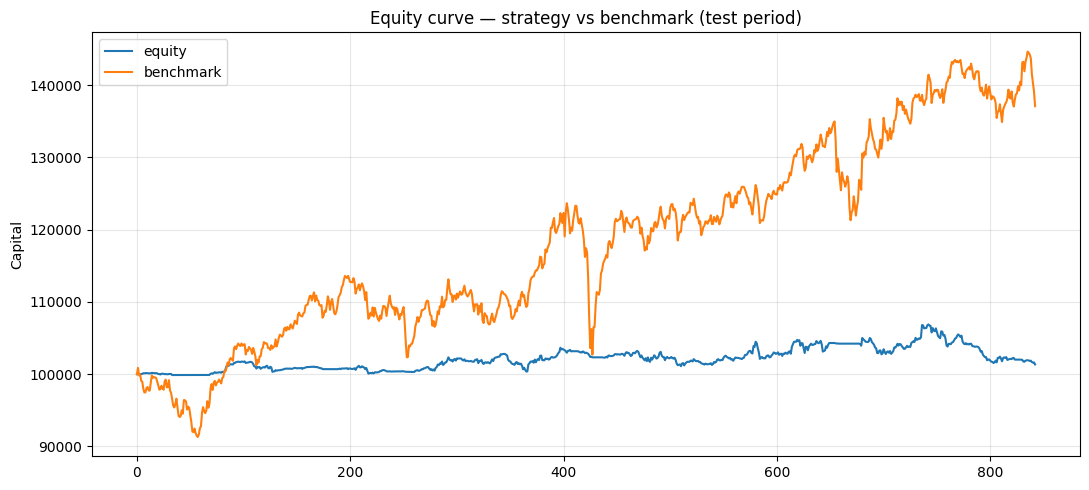

In [5]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import matplotlib.pyplot as plt
import os
ec_path  = os.path.join(_project_root, 'reports/equity_curve.csv')
bm_path  = os.path.join(_project_root, 'reports/benchmark_curve.csv')
eq = pd.read_csv(ec_path) if os.path.exists(ec_path) else None
bm = pd.read_csv(bm_path) if os.path.exists(bm_path) else None
if eq is not None:
    fig, ax = plt.subplots(figsize=(11,5))
    eq.plot(ax=ax, label='Strategy (risk-managed)')
    if bm is not None: bm.plot(ax=ax, label='Benchmark (equal-weight)')
    ax.set_title('Equity curve — strategy vs benchmark (test period)')
    ax.set_ylabel('Capital'); ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
else:
    print('equity_curve.csv not yet written.')
